# Supplementary figures

Reads saved results; nothing is computed here.

## Blobs: metric MDS from the classical-MDS initialization and from three random initializations

(a) The metric MDS of the main figure (SMACOF, started from classical MDS). (b-d) The same, started from random
configurations (ablation `mmds_random_init`, seeds 0, 1, 2). The number in the corner of each panel is its triplet
accuracy. Run first:

```
uv run python code/embed.py --datasets blobs --methods metric_mds
uv run python code/evaluate.py --datasets blobs --methods metric_mds
uv run python code/ablations.py embed --ablations mmds_random_init
uv run python code/ablations.py evaluate --ablations mmds_random_init
```

In [1]:
import sys
sys.path.insert(0, "..")  # make the modules in code/ importable

import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist

import paths
import results_io as rio
from ablations import ablation_jobs
from datasets import load_blobs
from plan import main_jobs

paths.FIGURES.mkdir(exist_ok=True)
if paths.STYLE.exists():
    plt.style.use(paths.STYLE)
else:
    print(f"{paths.STYLE} not found: using matplotlib's default style. Copy your mpl_style.txt there.")

Classical init.  stress-1 0.402   triplet accuracy 0.83   runtime 359 s
Random init. 0   stress-1 0.407   triplet accuracy 0.74   runtime 240 s
Random init. 1   stress-1 0.415   triplet accuracy 0.60   runtime 172 s
Random init. 2   stress-1 0.407   triplet accuracy 0.73   runtime 175 s


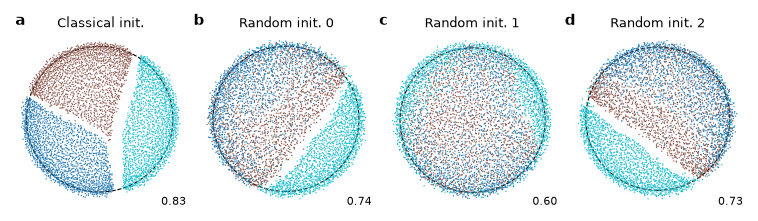

In [2]:
panels = [(main_jobs(["blobs"], ["metric_mds"], [0])[0], "Classical init.")]            # as in the main figure
panels += [(job, f"Random init. {job.seed}") for job in ablation_jobs(["mmds_random_init"], ["blobs"])]
for job, title in panels:
    if not job.emb_path.exists() or "triplet_acc" not in rio.load_metrics(job.metrics_path):
        raise FileNotFoundError(f"results for '{title}' are missing: run the four commands in the first cell")

X, y, _ = load_blobs()
distances = pdist(X)
radius = distances[distances > 0].mean() * np.pi / 4   # the circle drawn in the main figure

fig, axs = plt.subplots(ncols=len(panels), figsize=(5.5, 1.5), layout="constrained")
for ax, (job, title) in zip(axs, panels):
    Z = rio.load_embedding(job.emb_path)
    metrics = rio.load_metrics(job.metrics_path)
    ax.set_aspect("equal", adjustable="datalim")
    ax.scatter(Z[:, 0], Z[:, 1], s=2, ec="none", c=y, cmap="tab10", rasterized=True)
    ax.add_patch(plt.Circle((0, 0), radius, facecolor="none", edgecolor="k", linestyle="--", lw=.6, zorder=0))
    ax.set_axis_off()
    ax.set_title(title)
    ax.text(.99, .01, f"{metrics['triplet_acc']:.2f}", ha="right", transform=ax.transAxes)
    print(f"{title:16s} stress-1 {metrics['stress1_metric']:.3f}   triplet accuracy {metrics['triplet_acc']:.2f}"
          f"   runtime {rio.read_embedding_meta(job.emb_path)['runtime']:.0f} s")

for x, letter in zip([.01, .25, .50, .75], "abcd"):
    fig.text(x, .93, letter, fontweight="bold", fontsize=8)
for ext in ("png", "pdf"):
    fig.savefig(paths.FIGURES / f"blobs-random-init.{ext}", dpi=300)